In [1]:
# learning the implementation of decision tree algorithm using python
# on play tennis dataset

In [2]:
# loading the dataset 
import pandas as pd

data = pd.read_csv('play_tennis.csv')

In [ ]:
# undersanding the dataset
display(data.head(20))

# see details or info about columns and data types and non-null values
# data.info()

# to store the column details in a variable
columns = data.columns.to_list()

# checking our requirements for decision tree algorithm
outlook = data['outlook'].unique()

# checking total yes-no values in outlook column
data['outlook'].value_counts()
data['play'].value_counts()

#using cross tabulation to check the relationship between outlook and play columns
print('Cross tabulation between outlook and play columns')
display(pd.crosstab(data['outlook'], data['play'], margins=True))

# from result of this cross tabulation we can say there is leafnode 'Overcast' which say yes in all 
# condition while we have to make decision tree in other 
# two cases 

# realting the sunny and rainy outlook with play column using cross tabulation

# for sunny outlook
print('Cross tabulation for Sunny outlook')
display(pd.crosstab(
    [data.loc[data['outlook'] == 'Sunny', 'temp']],
    data.loc[data['outlook'] == 'Sunny', 'play'],
    margins=True
    )
)

# from this table we can see that hot is also a leafnode as in all cases play is no when temp is hot 
# also cool is a leafnode as in all cases play is yes when temp is cool
# again we have to make decision tree for mild temp when outlook is sunny
print('Cross tabulation for Sunny outlook and Mild temp and humidity')
display(pd.crosstab(
    [data.loc[(data['outlook'] == 'Sunny') & (data['temp'] == 'Mild'), 'humidity']],
    data.loc[(data['outlook'] == 'Sunny') & (data['temp'] == 'Mild'), 'play'],
    margins=True
    )
)

# same we try with column wind 
print('Cross tabulation for Sunny outlook and Mild temp and wind')
display(pd.crosstab(
    [data.loc[(data['outlook'] == 'Sunny') & (data['temp'] == 'Mild'), 'wind']],
    data.loc[(data['outlook'] == 'Sunny') & (data['temp'] == 'Mild'), 'play'],
    margins=True
    )
)


# for Rain outlook
print('Cross tabulation for Rain outlook')
display(pd.crosstab(
    [data.loc[data['outlook'] == 'Rain', 'temp']],
    data.loc[data['outlook'] == 'Rain', 'play'],
    margins=True
))

# from result of this table we can see that Mild and Cool temperatures
# have both Yes and No values, so they are not leaf nodes.
# We need to further analyze the Rain outlook based on temperature.

# checking Rain outlook with Cool temp and humidity
print('Cross tabulation for Rain outlook and Cool temp and humidity')
display(pd.crosstab(
    [data.loc[(data['outlook'] == 'Rain') & (data['temp'] == 'Cool'), 'humidity']],
    data.loc[(data['outlook'] == 'Rain') & (data['temp'] == 'Cool'), 'play'],
    margins=True
))

# checking Rain outlook with Cool temp and wind
print('Cross tabulation for Rain outlook and Cool temp and wind')
display(pd.crosstab(
    [data.loc[(data['outlook'] == 'Rain') & (data['temp'] == 'Cool'), 'wind']],
    data.loc[(data['outlook'] == 'Rain') & (data['temp'] == 'Cool'), 'play'],
    margins=True
))

# checking Rain outlook with Mild temp and humidity
print('Cross tabulation for Rain outlook and Mild temp and humidity')
display(pd.crosstab(
    [data.loc[(data['outlook'] == 'Rain') & (data['temp'] == 'Mild'), 'humidity']],
    data.loc[(data['outlook'] == 'Rain') & (data['temp'] == 'Mild'), 'play'],
    margins=True
))

# checking Rain outlook with Mild temp and wind
print('Cross tabulation for Rain outlook and Mild temp and wind')
display(pd.crosstab(
    [data.loc[(data['outlook'] == 'Rain') & (data['temp'] == 'Mild'), 'wind']],
    data.loc[(data['outlook'] == 'Rain') & (data['temp'] == 'Mild'), 'play'],
    margins=True
))



,day,outlook,temp,humidity,wind,play
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes
5,D6,Rain,Cool,Normal,Strong,No
6,D7,Overcast,Cool,Normal,Strong,Yes
7,D8,Sunny,Mild,High,Weak,No
8,D9,Sunny,Cool,Normal,Weak,Yes
9,D10,Rain,Mild,Normal,Weak,Yes


Cross tabulation between outlook and play columns


play,No,Yes,All
outlook,,,
Overcast,0,4,4
Rain,2,3,5
Sunny,3,2,5
All,5,9,14


Cross tabulation for Sunny outlook


play,No,Yes,All
temp,,,
Cool,0,1,1
Hot,2,0,2
Mild,1,1,2
All,3,2,5


...

play,No,Yes,All
wind,,,
Strong,1,0,1
Weak,0,1,1
All,1,1,2


Cross tabulation for Rain outlook and Mild temp and humidity


play,No,Yes,All
humidity,,,
High,1,1,2
Normal,0,1,1
All,1,2,3


Cross tabulation for Rain outlook and Mild temp and wind


play,No,Yes,All
wind,,,
Strong,1,0,1
Weak,0,2,2
All,1,2,3


In [ ]:
# conclusion from above analysis:

# Decision Tree — Play Tennis Dataset Analysis

## 1. Understanding the Dataset

The dataset contains weather conditions and the decision to play tennis.

```python
display(data.head(20))
```

To inspect column information, data types, and non-null values:

```python
data.info()
```

To store all column names in a list:

```python
columns = data.columns.to_list()
```

To find unique values in the `outlook` column:

```python
outlook = data['outlook'].unique()
```

To count the occurrences of each value:

```python
data['outlook'].value_counts()
data['play'].value_counts()
```

### Dataset attributes

- **day:** Day identifier
- **outlook:** Sunny, Overcast, Rain
- **temp:** Hot, Mild, Cool
- **humidity:** High, Normal
- **wind:** Weak, Strong
- **play:** Yes, No (target variable)

## 2. Cross-Tabulation: Outlook vs Play

```python
pd.crosstab(data['outlook'], data['play'], margins=True)
```

| Outlook | No | Yes | Total |
|---|---:|---:|---:|
| Overcast | 0 | 4 | 4 |
| Rain | 2 | 3 | 5 |
| Sunny | 3 | 2 | 5 |
| **Total** | **5** | **9** | **14** |

### Observations

- **Overcast:** All 4 observations have `play = Yes`. This is a pure leaf node.
- **Sunny:** 3 No and 2 Yes. Further splitting is required.
- **Rain:** 2 No and 3 Yes. Further splitting is required.

Therefore, `outlook` is a useful initial decision-tree splitting attribute.

## 3. Sunny Outlook Analysis

### 3.1 Sunny: Temperature vs Play

```python
pd.crosstab(
    data.loc[data['outlook'] == 'Sunny', 'temp'],
    data.loc[data['outlook'] == 'Sunny', 'play'],
    margins=True
)
```

| Temperature | No | Yes | Total |
|---|---:|---:|---:|
| Cool | 0 | 1 | 1 |
| Hot | 2 | 0 | 2 |
| Mild | 1 | 1 | 2 |
| **Total** | **3** | **2** | **5** |

**Observations:**

- **Hot:** All observations are No — pure leaf node.
- **Cool:** All observations are Yes — pure leaf node.
- **Mild:** Contains both Yes and No — further splitting is required.

### 3.2 Sunny + Mild: Humidity vs Play

```python
pd.crosstab(
    data.loc[
        (data['outlook'] == 'Sunny') & (data['temp'] == 'Mild'),
        'humidity'
    ],
    data.loc[
        (data['outlook'] == 'Sunny') & (data['temp'] == 'Mild'),
        'play'
    ],
    margins=True
)
```

| Humidity | No | Yes | Total |
|---|---:|---:|---:|
| High | 1 | 0 | 1 |
| Normal | 0 | 1 | 1 |
| **Total** | **1** | **1** | **2** |

**Observation:** Humidity perfectly separates the two observations.

- High → No
- Normal → Yes

Both outcomes are pure leaf nodes.

### 3.3 Sunny + Mild: Wind vs Play

```python
pd.crosstab(
    data.loc[
        (data['outlook'] == 'Sunny') & (data['temp'] == 'Mild'),
        'wind'
    ],
    data.loc[
        (data['outlook'] == 'Sunny') & (data['temp'] == 'Mild'),
        'play'
    ],
    margins=True
)
```

| Wind | No | Yes | Total |
|---|---:|---:|---:|
| Strong | 0 | 1 | 1 |
| Weak | 1 | 0 | 1 |
| **Total** | **1** | **1** | **2** |

**Observation:** Wind also perfectly separates the outcomes.

- Strong → Yes
- Weak → No

Both humidity and wind can classify these two observations perfectly. Choosing between them requires a criterion such as information gain or Gini impurity.

## 4. Rain Outlook Analysis

### 4.1 Rain: Temperature vs Play

```python
pd.crosstab(
    data.loc[data['outlook'] == 'Rain', 'temp'],
    data.loc[data['outlook'] == 'Rain', 'play'],
    margins=True
)
```

| Temperature | No | Yes | Total |
|---|---:|---:|---:|
| Cool | 1 | 1 | 2 |
| Mild | 1 | 2 | 3 |
| **Total** | **2** | **3** | **5** |

**Observations:**

- **Cool:** Contains both Yes and No.
- **Mild:** Contains both Yes and No.
- **Hot:** No observations exist for Rain + Hot.

Neither Cool nor Mild is a pure leaf node, so further analysis is needed.

### 4.2 Rain + Cool: Humidity vs Play

```python
pd.crosstab(
    data.loc[
        (data['outlook'] == 'Rain') & (data['temp'] == 'Cool'),
        'humidity'
    ],
    data.loc[
        (data['outlook'] == 'Rain') & (data['temp'] == 'Cool'),
        'play'
    ],
    margins=True
)
```

| Humidity | No | Yes | Total |
|---|---:|---:|---:|
| Normal | 1 | 1 | 2 |
| **Total** | **1** | **1** | **2** |

**Observation:** Humidity cannot separate the outcomes because both observations have Normal humidity, with one Yes and one No.

### 4.3 Rain + Cool: Wind vs Play

```python
pd.crosstab(
    data.loc[
        (data['outlook'] == 'Rain') & (data['temp'] == 'Cool'),
        'wind'
    ],
    data.loc[
        (data['outlook'] == 'Rain') & (data['temp'] == 'Cool'),
        'play'
    ],
    margins=True
)
```

| Wind | No | Yes | Total |
|---|---:|---:|---:|
| Strong | 1 | 0 | 1 |
| Weak | 0 | 1 | 1 |
| **Total** | **1** | **1** | **2** |

**Observation:** Wind perfectly separates the outcomes.

- Strong → No
- Weak → Yes

Both outcomes are pure leaf nodes.

### 4.4 Rain + Mild: Humidity vs Play

```python
pd.crosstab(
    data.loc[
        (data['outlook'] == 'Rain') & (data['temp'] == 'Mild'),
        'humidity'
    ],
    data.loc[
        (data['outlook'] == 'Rain') & (data['temp'] == 'Mild'),
        'play'
    ],
    margins=True
)
```

| Humidity | No | Yes | Total |
|---|---:|---:|---:|
| High | 1 | 1 | 2 |
| Normal | 0 | 1 | 1 |
| **Total** | **1** | **2** | **3** |

**Observation:**

- Normal → Yes (pure leaf node).
- High → Contains one Yes and one No, so further splitting is required.

### 4.5 Rain + Mild + High Humidity: Wind vs Play

```python
pd.crosstab(
    data.loc[
        (data['outlook'] == 'Rain') &
        (data['temp'] == 'Mild') &
        (data['humidity'] == 'High'),
        'wind'
    ],
    data.loc[
        (data['outlook'] == 'Rain') &
        (data['temp'] == 'Mild') &
        (data['humidity'] == 'High'),
        'play'
    ],
    margins=True
)
```

| Wind | No | Yes | Total |
|---|---:|---:|---:|
| Strong | 1 | 0 | 1 |
| Weak | 0 | 1 | 1 |
| **Total** | **1** | **1** | **2** |

**Observation:** Wind perfectly separates the remaining observations.

- Strong → No
- Weak → Yes

Both outcomes are pure leaf nodes.

## 5. Final Decision-Tree Rules

Based on the observed data, the following rules classify all 14 training examples correctly:

1. If `outlook = Overcast` → **Yes**
2. If `outlook = Sunny`:
   - If `temp = Hot` → **No**
   - If `temp = Cool` → **Yes**
   - If `temp = Mild`:
     - If `humidity = High` → **No**
     - If `humidity = Normal` → **Yes**
3. If `outlook = Rain`:
   - If `temp = Cool`:
     - If `wind = Strong` → **No**
     - If `wind = Weak` → **Yes**
   - If `temp = Mild`:
     - If `humidity = Normal` → **Yes**
     - If `humidity = High`:
       - If `wind = Strong` → **No**
       - If `wind = Weak` → **Yes**


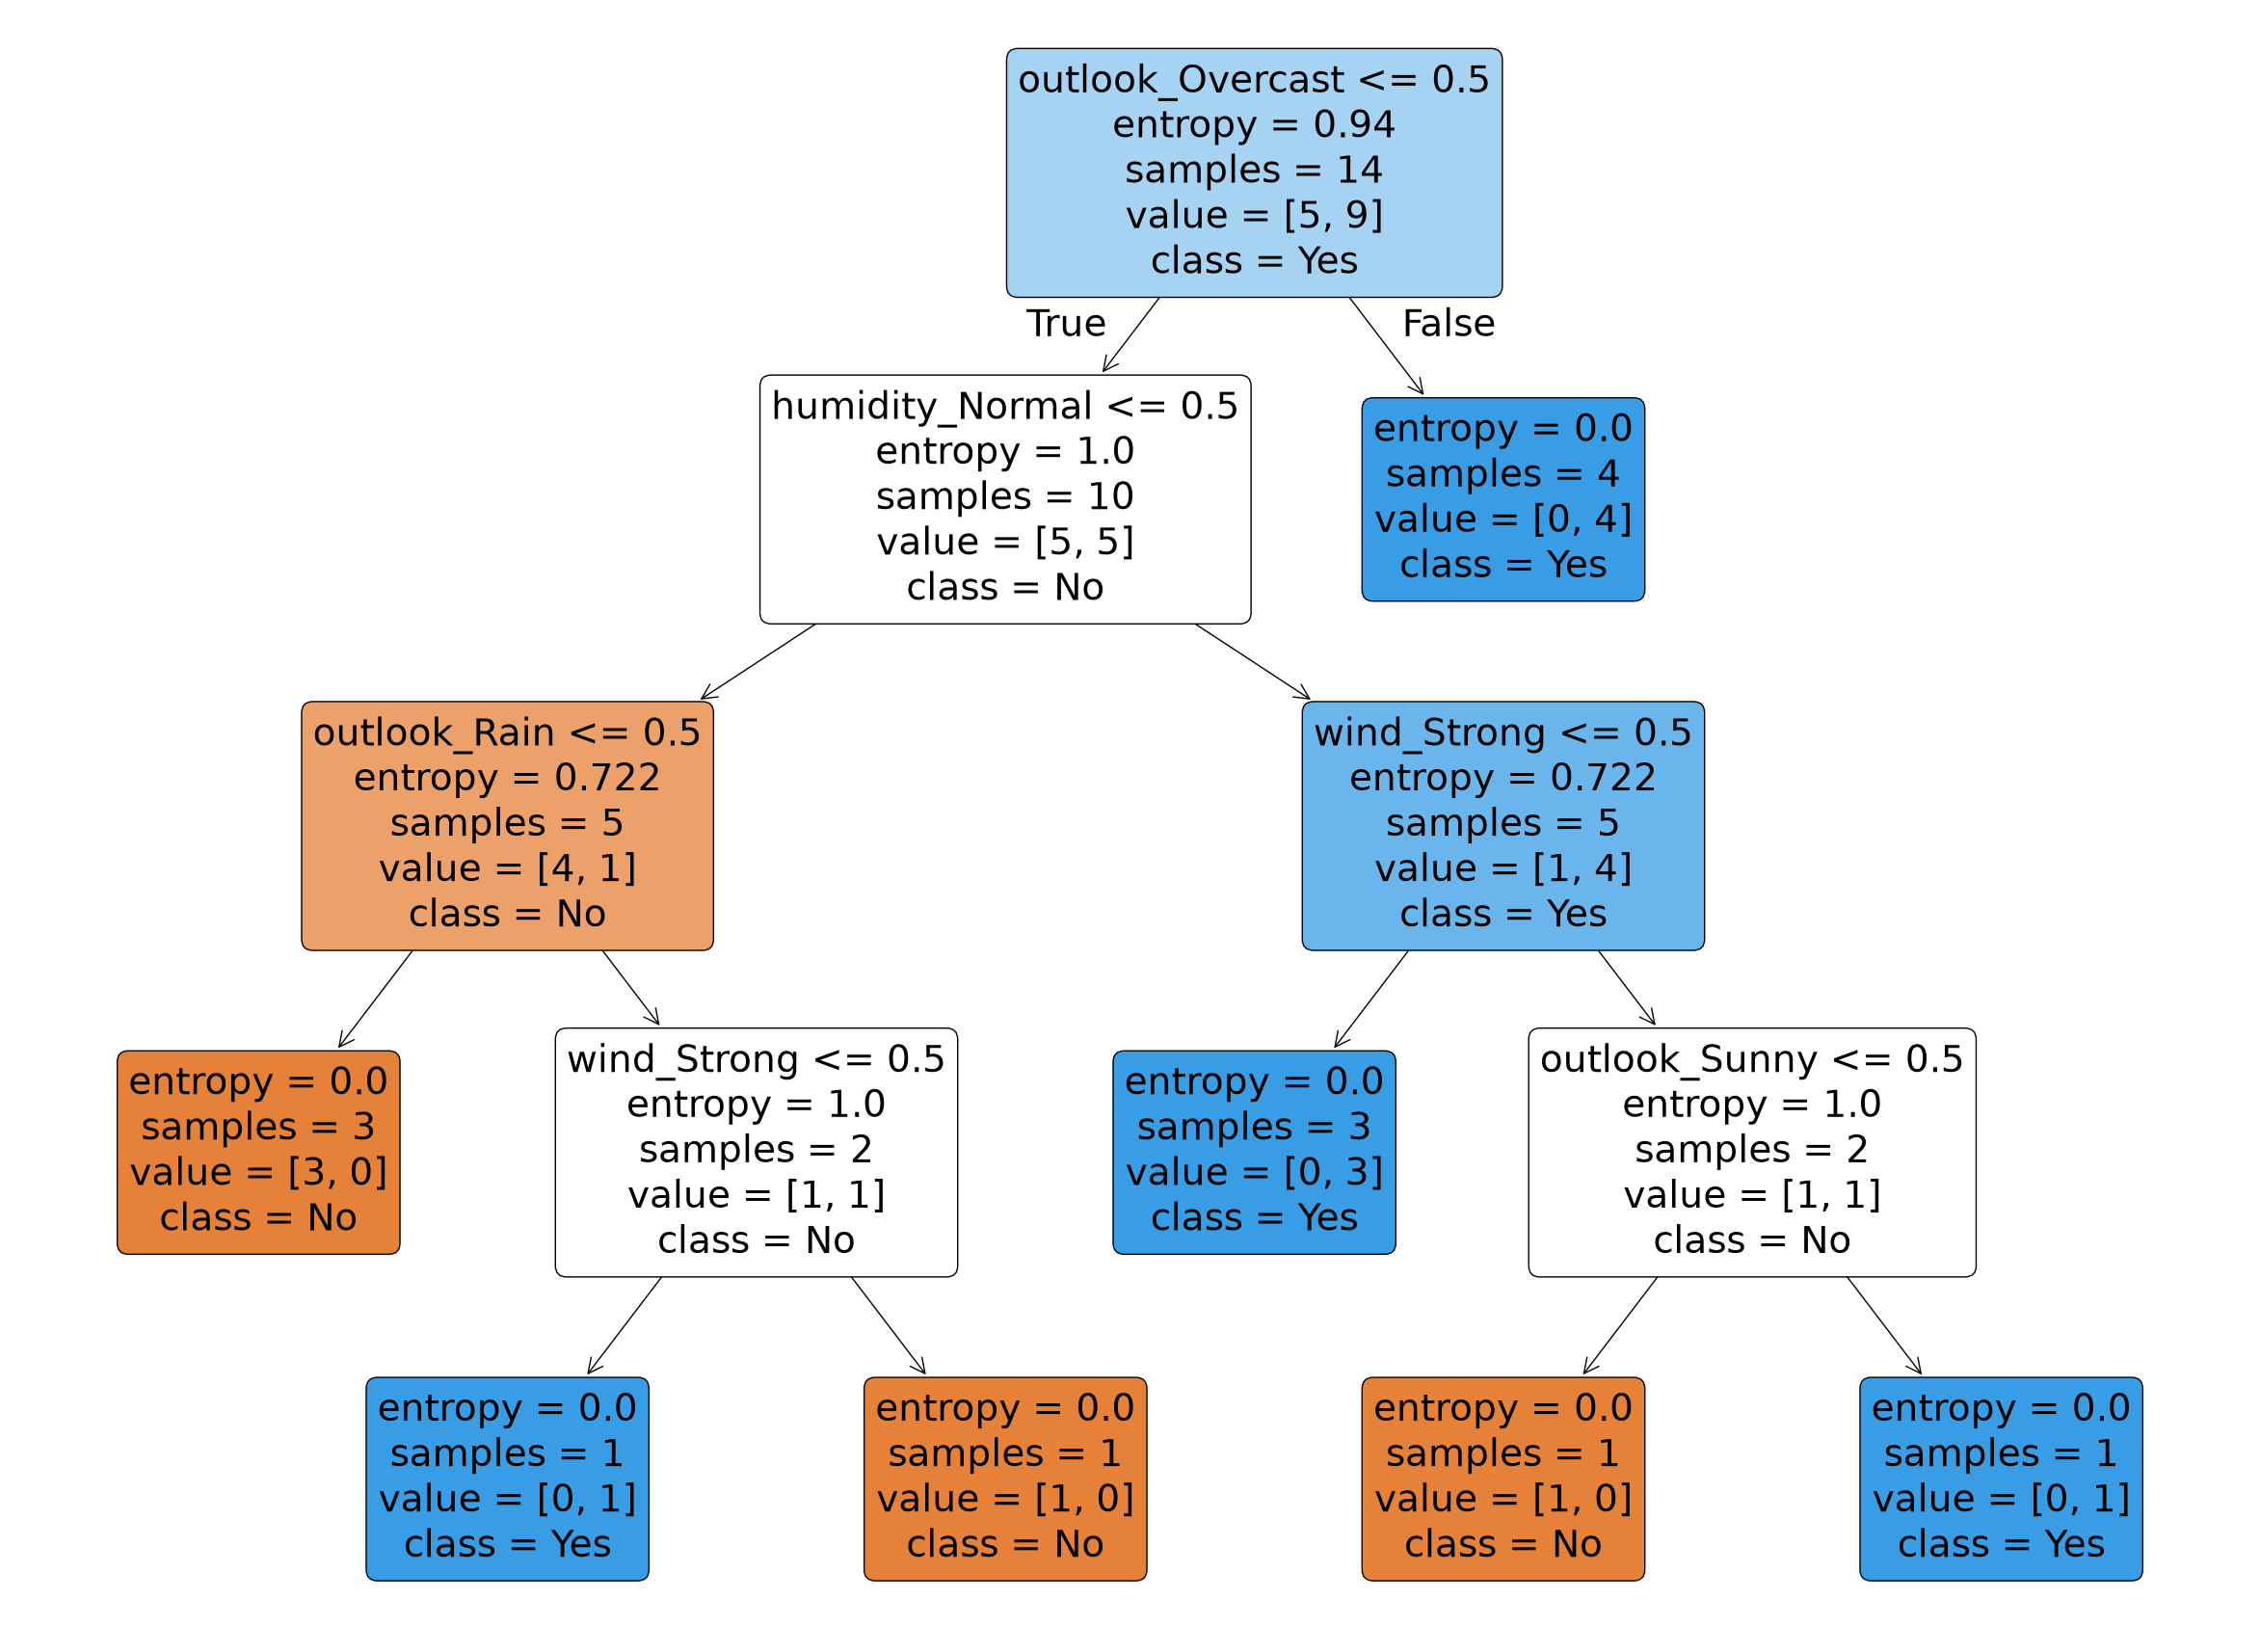

Training accuracy: 1.0


In [38]:
# learning --- IGNORE ---
# using the predefined decision tree algorithm from sklearn library to make decision tree for play tennis dataset

from matplotlib import pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# now first we have to choose the input variables 
X = pd.get_dummies(
    data.drop(columns=['play' , 'day']) , 
    dtype = 'int'
)

# target variable or outpur variable 
y = data['play'].map(
    {
        'Yes': 1, 
        'No': 0
    }
)

# model creation 
model = DecisionTreeClassifier(
    criterion='entropy', 
    random_state=42
)

# training the model
model.fit(X, y)

# ploting the obtained output decision tree
plt.figure(figsize=(30, 22))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=['No', 'Yes'],
    filled=True,
    rounded=True
)

plt.show()

# output the accuracy of the model on training data
y_pred = model.predict(X)
print("Training accuracy:", accuracy_score(y, y_pred))


## Entropy
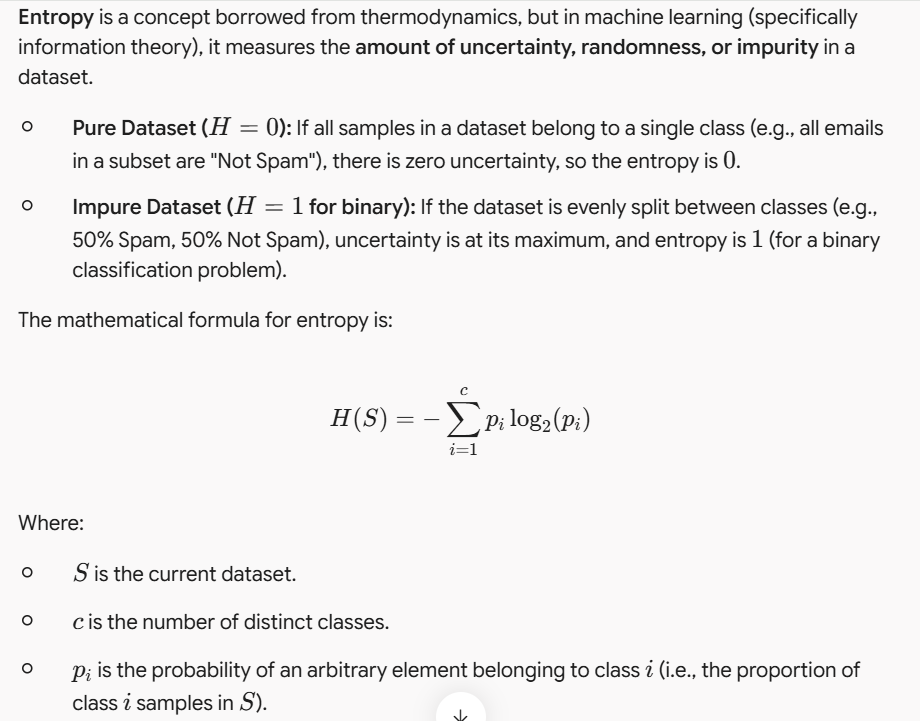

## Information Gain
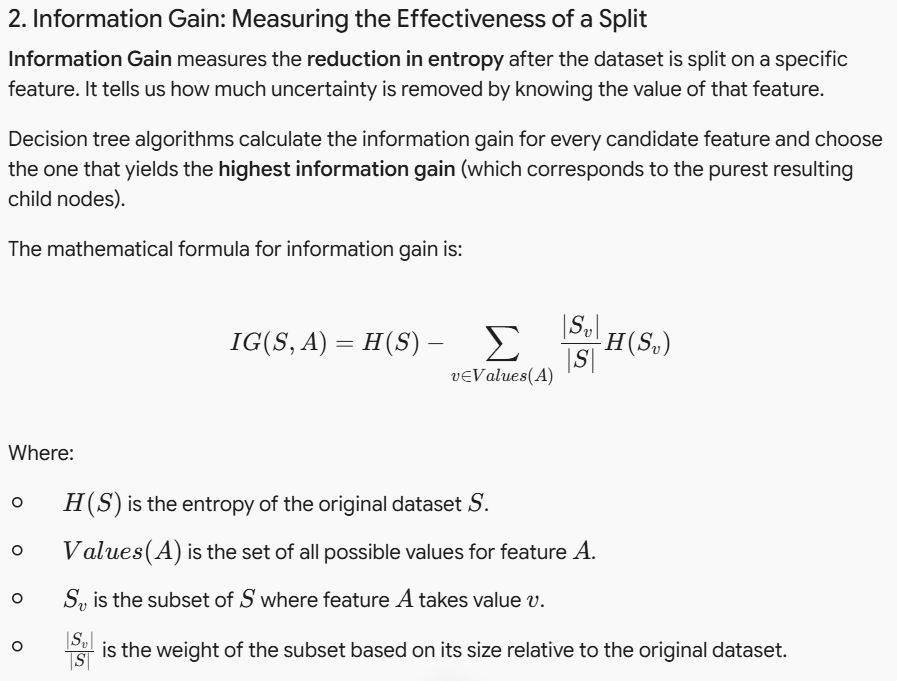
